# Support: how often do two items share a basket?

**Week 4, Wednesday, chapter 1 of the concept block.** The topic, in the curriculum's words: *Support, confidence and lift, derived by counting*.
The examples are invented for this chapter, small enough to count by hand: every number below is counted from a table in `data/`, and the code only confirms the count.

**Who needs the answer.** The canteen manager, who prints two items side by side on the combo board; without a count, the board goes to whichever pair the manager remembers selling.

**The questions on the way.** What is a basket? How many orders hold both roti and sabzi? Which pair is most common? What does support leave out?

In [1]:
def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)
    assert ok, name
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})
import pandas as pd
from collections import Counter
from itertools import combinations

lines = pd.read_csv("../data/C2_W04_D03_canteen_order_lines_STUDENT.csv")
listed = lines.groupby("order_id").item.apply(list)      # the items in the order the bill lists them
baskets = listed.apply(set)                               # one set of items per order
n = len(baskets)
print("A hostel canteen's twelve lunch orders, invented for the concept chapters:")
for order_id, held in listed.items():
    print(f"  {order_id}: {', '.join(held)}")


def has(item):
    """True for every order that holds the item."""
    return baskets.apply(lambda b: item in b)


check("twelve orders and 33 order lines", n == 12 and len(lines) == 33)

A hostel canteen's twelve lunch orders, invented for the concept chapters:
  T01: dal rice, papad, chaas
  T02: dal rice, papad, chaas
  T03: dal rice, papad, chaas
  T04: dal rice, sabzi, chaas
  T05: dal rice, chaas
  T06: dal rice, curd, chaas
  T07: roti, papad, pickle
  T08: papad, pickle
  T09: roti, sabzi, chaas
  T10: roti, sabzi, chaas
  T11: roti, sabzi, chaas
  T12: gulab jamun, curd
PASS twelve orders and 33 order lines


## How many of the twelve orders hold roti and sabzi?

A **basket** is everything one customer pays for in one go: one bill at a kirana, one
order at the canteen, one cart on an app. Together means in the same basket. Roti is in 4
orders and sabzi in 4.

**Predict before you run.** How many orders hold both?

a) 8, since four roti orders and four sabzi orders make eight.
b) 5, since five orders hold roti or sabzi.
c) 3, since three orders hold roti with sabzi.
d) 4, since every roti order also holds sabzi.

In [2]:
roti, sabzi = has("roti"), has("sabzi")
both = (roti & sabzi).sum()
print(f"roti in {roti.sum()} orders, sabzi in {sabzi.sum()}")
print(f"both {both}, roti only {(roti & ~sabzi).sum()}, sabzi only {(sabzi & ~roti).sum()}, "
      f"neither {(~roti & ~sabzi).sum()}")
print(f"support of roti and sabzi: {both} / {n} = {both / n:.2f}")
print(f"adding the two counts gives {roti.sum() + sabzi.sum()}, which counts the same orders twice")
check("the four cells of the 2 by 2 add to twelve",
      both + (roti & ~sabzi).sum() + (sabzi & ~roti).sum() + (~roti & ~sabzi).sum() == n)
check("support of roti and sabzi is 0.25", both / n == 0.25)

roti in 4 orders, sabzi in 4
both 3, roti only 1, sabzi only 1, neither 7
support of roti and sabzi: 3 / 12 = 0.25
adding the two counts gives 8, which counts the same orders twice
PASS the four cells of the 2 by 2 add to twelve
PASS support of roti and sabzi is 0.25


**What happened.** The answer is c: T09, T10 and T11 hold both, so support is
3 / 12 = 0.25. **The plausible wrong answer** is 8, which
adds the two counts and never looks inside an order, so T09 to T11 are counted twice. The
check is the 2 by 2 table below: its four cells, both, roti only, sabzi only and neither,
must add to twelve. Support is a rate, and its denominator is every basket, as every rate
since Week 1 Monday named its denominator.

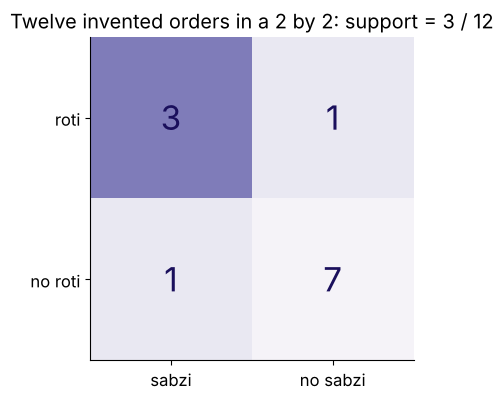

In [3]:
grid = [[both, (roti & ~sabzi).sum()], [(sabzi & ~roti).sum(), (~roti & ~sabzi).sum()]]
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.imshow([[1, 0.25], [0.25, 0.1]], cmap="Purples", vmin=0, vmax=1.6)
for i in range(2):
    for j in range(2):
        ax.text(j, i, grid[i][j], ha="center", va="center", fontsize=24, color="#1A0F5C")
ax.set_xticks([0, 1], ["sabzi", "no sabzi"])
ax.set_yticks([0, 1], ["roti", "no roti"])
ax.set_title("Twelve invented orders in a 2 by 2: support = 3 / 12")
plt.show()

## Which pair is the most common?

Every order adds one to the tally of every two items it holds. Sorting the two names first
keeps "dal rice with chaas" and "chaas with dal rice" as one pair; chapter 5 explains why.
The support of a pair is its count over all twelve orders.

chaas + dal rice: 6 orders, support 0.50
chaas + sabzi: 4 orders, support 0.33
chaas + papad: 3 orders, support 0.25
dal rice + papad: 3 orders, support 0.25
chaas + roti: 3 orders, support 0.25
roti + sabzi: 3 orders, support 0.25


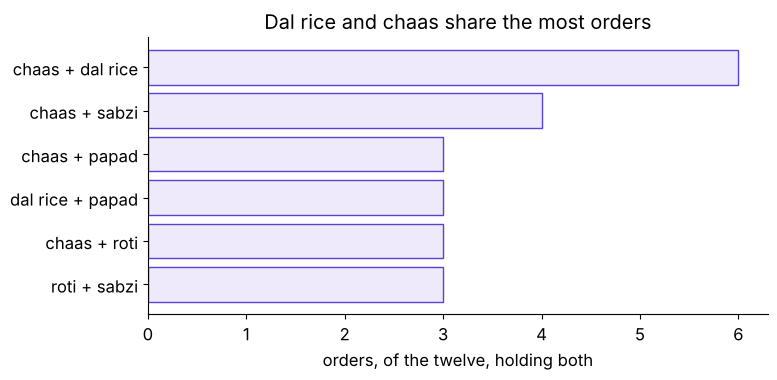

PASS dal rice and chaas share 6 orders


In [4]:
pair_count = Counter(p for b in baskets for p in combinations(sorted(b), 2))
top = pair_count.most_common(6)
for (a, b), k in top:
    print(f"{a} + {b}: {k} orders, support {k / n:.2f}")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh([f"{a} + {b}" for (a, b), _ in top][::-1], [k for _, k in top][::-1],
        color="#EEEAFB", edgecolor="#5B3FD6")
ax.set_xlabel("orders, of the twelve, holding both")
ax.set_title("Dal rice and chaas share the most orders")
plt.show()
check("dal rice and chaas share 6 orders", pair_count[("chaas", "dal rice")] == 6)

## What is one item's own support?

An item on its own has a support too: its share of all baskets. Chaas is in
9 of the twelve orders, a share of
0.75, which is why four of the six most common pairs hold chaas.
Whether the most common pair is the best one for the combo board is a different question,
and chapter 4 answers it.

chaas          0.75
dal rice       0.50
papad          0.42
sabzi          0.33
roti           0.33
curd           0.17
pickle         0.17
gulab jamun    0.08


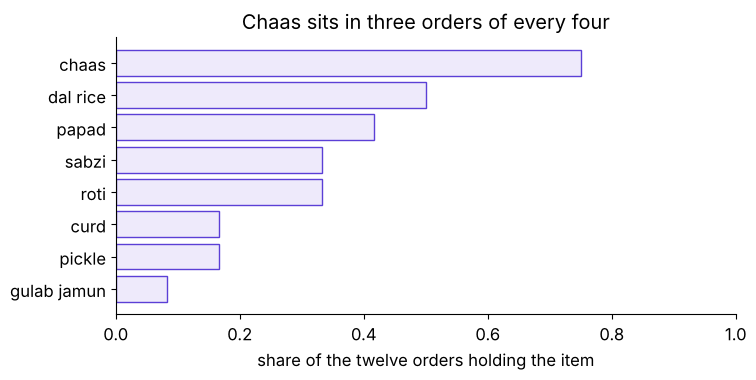

PASS chaas sits in 0.75 of the orders


In [5]:
single = Counter(x for b in baskets for x in b)
share = pd.Series(single).sort_values(ascending=False) / n
print(share.round(2).to_string())
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(share.index[::-1], share.values[::-1], color="#EEEAFB", edgecolor="#5B3FD6")
ax.set_xlim(0, 1)
ax.set_xlabel("share of the twelve orders holding the item")
ax.set_title("Chaas sits in three orders of every four")
plt.show()
check("chaas sits in 0.75 of the orders", share["chaas"] == 0.75)

### Your turn: what is the support of papad and pickle?

Papad is in 5 orders and pickle in 2. In the empty cell below, count the orders holding
both and divide by all orders, the way the roti and sabzi cell did, and store the answer
as `papad_pickle`. Then run the check under it, which prints the reference and compares
your number with it.

In [6]:
reference = (has("papad") & has("pickle")).sum() / n
mine = globals().get("papad_pickle")
print(f"reference: {reference:.2f}" + ("" if mine is None else f"; yours: {mine:.2f}"))
check("papad and pickle: support 0.17", round(reference, 2) == 0.17)
if mine is not None:
    check("your support matches the reference", abs(mine - reference) < 1e-9)

reference: 0.17
PASS papad and pickle: support 0.17


## What should you keep from chapter 1?

- A basket is everything one customer pays for in one go, and together means in the same
  basket.
- Support of a pair is the baskets holding both over all baskets, so its denominator is
  every basket: roti and sabzi 0.25.
- An item's own support is its share of baskets: chaas 0.75.
- The most common pair is a count and nothing more yet. Roti and sabzi and roti and chaas
  both read 0.25, so support cannot tell them apart;
  notebook 02 adds confidence and notebook 03 adds lift.

**In the interview.** "What is support?" The share of all baskets that hold both items,
said with its denominator. Chapter 7 counts it again on twelve of Instamart's carts.